# Physics-Informed Neural Networks for Electromagnetic Field Prediction

## Introduction

While traditional deep learning models learn mappings purely from data, **Physics-Informed Neural Networks (PINNs)** integrate physical laws directly into the learning process {cite}`raissi2019physics,karniadakis2021physics`. This approach is particularly valuable for electromagnetic field prediction where Maxwell's equations provide rigorous governing constraints {cite}`sadiku2014elements,ida2015numerical`.

**Chapter context**: Sections 1.4 & 1.5 developed data-driven CNNs with uncertainty quantification, achieving 0.3-0.6% NMSE on magnetic field prediction. However, these models required 30,000+ FEA training samples and provided no guarantee of physics consistency.

**PINN alternative**: This section explores an orthogonal paradigm - incorporating Maxwell's equations as soft constraints during training—enabling physics-consistent predictions from sparse data {cite}`raissi2019physics,cai2021physics`.

### Key Advantages of PINNs for Electromagnetics

1. **Physics consistency** {cite}`raissi2019physics,karniadakis2021physics`: Predictions automatically satisfy Maxwell's equations
- ∇×**H** = **J** (Ampere's law)
- ∇·**B** = 0 (Gauss's law for magnetism)
- Boundary conditions enforced via loss function

2. **Data efficiency** {cite}`cai2021physics,yang2021adversarial`: Learn from sparse observations (10-100 points vs. 30,000 for pure data-driven)
- Physics constraints regularize solution space
- Prior knowledge reduces dependence on data

3. **Improved extrapolation** {cite}`raissi2019physics`: Better generalization to unseen parameter regimes
- Physical laws hold beyond training distribution
- Reduces epistemic uncertainty from Chapter 5

4. **Inverse problem capability** {cite}`raissi2017physics,karniadakis2021physics`: Simultaneously solve for unknowns:
- Forward: Geometry -> field (standard prediction)
- Inverse: Field measurements -> material properties, source currents


## Literature Survey: PINNs in Computational Electromagnetics

### Foundations of Physics-Informed Neural Networks

The concept of Physics-Informed Neural Networks was formalized by Raissi, Perdikaris, and Karniadakis (2019) {cite}`raissi2019physics` in their seminal work demonstrating that neural networks can solve forward and inverse problems governed by partial differential equations. Subsequent developments {cite}`karniadakis2021physics,cai2021physics` established PINNs as a powerful framework for scientific machine learning.

**Core innovations** {cite}`raissi2019physics,baydin2018automatic`:
- **Automatic differentiation**: Compute spatial/temporal derivatives via backpropagation
- **Collocation methods**: Enforce PDEs at randomly sampled points in the domain
- **Soft constraints**: Physics incorporated via loss function penalties (not hard constraints)
- **Multi-task learning**: Simultaneously optimize data fit and physics satisfaction

**Theoretical justification**: PINNs approximate the solution to PDEs by minimizing the L² norm of the PDE residual, equivalent to variational methods in numerical analysis {cite}`karniadakis2021physics,raissi2017physics`.

### Applications in Computational Electromagnetics

#### 1. Magnetostatic Field Prediction

**Barmada et al. (2020)** {cite}`barmada2020deep`: First application of deep learning to transformer magnetic fields
- Problem: 2D magnetostatic field distribution in power transformers
- Approach: Feedforward NN with physics-informed training
- Results: 10,000× speedup vs. FEA with < 1% error
- **Key contribution**: Demonstrated PINNs work for nonlinear B-H characteristics

**Chen et al. (2022)** {cite}`chen2022pinn`: Extended PINNs to rotating electrical machines
- Problem: Interior Permanent Magnet (IPM) motor with saturation
- Innovation: Adaptive collocation sampling near material boundaries
- Results: Accurate torque prediction with only 50 training samples

#### 2. Electrostatic Problems

**Henning & Stewart (2020)** {cite}`henning2020physics`: Solved 2D Poisson's equation for electrostatic potential
- PDE: $\nabla^2 \phi = -\rho/\epsilon_0$
- Achievement: Complex geometries without explicit mesh generation
- Limitation: Struggled with sharp corner singularities

**Stein et al. (2021)** {cite}`stein2021deep`: Applied PINNs to capacitance extraction
- Industrial application: VLSI interconnect parasitic extraction
- Data efficiency: 90% reduction in required field simulations

#### 3. Time-Harmonic Electromagnetic Waves

**Gao et al. (2021)** {cite}`gao2021physics`: Time-harmonic Maxwell's equations for eddy currents
- PDEs: $\nabla \times (\nabla \times \mathbf{E}) - k^2 \mathbf{E} = -j\omega\mu \mathbf{J}$
- Application: Skin effect and proximity effect in conductors
- Frequency range: 50 Hz - 10 kHz (power electronics)
- **Challenge**: Complex-valued networks for phasor representation

**Rasht-Behesht et al. (2022)** {cite}`rasht2022physics`: Full 3D Maxwell solver using PINNs
- Achievement: No meshing required for arbitrary geometries
- Computational cost: 10× longer training than FEA, but reusable for parameter sweeps

#### 4. Inverse Problems in Electromagnetics

**Wang et al. (2022)** {cite}`wang2022inverse`: Material property identification from field measurements
- Problem: Given sparse B-field measurements, infer permeability $\mu_r(x,y)$
- Method: Treat $\mu_r$ as learnable parameters alongside network weights
- Application: Non-destructive testing, defect detection in steel
- Results: Reconstructed $\mu_r$ with 5% accuracy from 20 measurement points

**Karniadakis et al. (2021)** {cite}`karniadakis2021physics`: Comprehensive review of PINN inverse methods
- Source localization: Identify current distribution from external field measurements
- Boundary condition inference: Determine unknown BCs from interior field data

### Comparison with Traditional Numerical Methods

| Aspect | FEA {cite}`ida2015numerical` | Boundary Element Method {cite}`brebbia1984boundary` | Traditional DL | PINNs {cite}`raissi2019physics` |
|--------|-----|-----|----------------|-------|
| **Mesh Required** | Yes (critical) | Boundary only | No | No |
| **Data Requirements** | None (physics solver) | None | High (10k+) | Low (10-100) |
| **Physics Consistency** | Exact (to discretization) | Exact | No guarantee | Enforced (soft) |
| **Inference Speed** | Slow (minutes) | Medium | Very Fast (ms) | Very Fast (ms) |
| **Extrapolation** | N/A | N/A | Poor | Good |
| **Training Cost** | N/A | N/A | Moderate | High (autodiff) |
| **Nonlinear Materials** | Yes | Limited | Yes | Yes |

:::{note}
**When PINNs excel vs. FEA** 

**PINN advantages** {cite}`cai2021physics,karniadakis2021physics`:
1. **Parametric studies**: Once trained, instant evaluation across parameter space
2. **Inverse problems**: Naturally handle parameter identification
3. **Sparse data**: Augment limited measurements with physics
4. **Mesh-free**: Complex geometries without mesh generation expertise

**FEA advantages** {cite}`ida2015numerical,meeker2015femm`:
1. **Accuracy**: Sub-0.1% error with sufficient mesh refinement
2. **Maturity**: 50+ years of development, extensive validation
3. **Industrial acceptance**: Regulatory approval, standardized workflows
4. **Complex physics**: Multi-physics coupling (thermal, mechanical, electromagnetic)

**Recommendation**: Use PINNs for exploration, FEA for validation.
:::

### Current Limitations and Active Research Directions

**Training difficulties** {cite}`wang2021understanding,wang2021eigenvector`:
1. **Loss balancing**: Choosing $\lambda$ to balance data vs. physics losses
- Too high: Underfit data (physics dominates)
- Too low: Violate physics (data dominates)
- **Solution**: Adaptive weighting schemes {cite}`wang2021understanding`

2. **Multi-scale phenomena** {cite}`jagtap2020extended`:
- Sharp gradients at boundaries challenge uniform collocation
- **Solution**: Adaptive sampling, domain decomposition (XPINNs)

3. **Convergence speed**:
- Standard Adam optimizer often struggles
- **Solution**: L-BFGS second-order optimization {cite}`liu1989limited`

**Complex geometries** {cite}`sukumar2022exact`:
- Material interfaces with discontinuous derivatives
- **Approaches**: Exact imposition of BCs {cite}`sukumar2022exact`, interface-aware sampling

**Recent methodological advances** {cite}`karniadakis2021physics,cai2021physics`:
- **Extended PINNs (XPINNs)** {cite}`jagtap2020extended`: Domain decomposition for parallel training
- **Conservative PINNs (cPINNs)** {cite}`jagtap2020conservative`: Enforce conservation laws explicitly
- **Multi-fidelity PINNs** {cite}`meng2020multi`: Combine low-fidelity analytical + high-fidelity FEA data
- **Adaptive collocation** {cite}`wu2023comprehensive`: Dynamic sampling based on residual magnitude

:::{tip}
**Emerging Hybrid Approaches** 

Most promising direction: **Combine PINNs with traditional methods** {cite}`yang2021adversarial,geneva2020modeling`:
1. **PINN pretraining + data finetuning**: Physics initialization, then refine with FEA
2. **Multi-fidelity**: PINN for cheap approximation, FEA for accuracy verification
3. **Physics-guided active learning**: Use PINN residuals to guide FEA sample collection

**Result**: Physics consistency + data accuracy, achieving best of both paradigms.
:::

## Scope of the PINN Section

This section presents a focused, end-to-end treatment of **Physics-Informed Neural Networks (PINNs)** for magnetostatic field prediction, organized into two consolidated notebooks. The emphasis is on formulation, implementation, and validation rather than repeated motivation.

---

### Section 6a — Theory and Problem Formulation (This Notebook)

This notebook establishes the **mathematical and physical foundation** required to apply PINNs to magnetostatic problems.

**Scope**:
- Governing equations for 2D magnetostatics {cite}`sadiku2014elements`
  - Ampère’s law: $\nabla \times \mathbf{H} = \mathbf{J}$
  - Gauss’s law for magnetism: $\nabla \cdot \mathbf{B} = 0$
- Boundary and interface conditions relevant to electromagnetic domains
- Problem specification for physics-informed learning
- Collocation concepts for enforcing PDE constraints
- The **FEMM coil dataset** as the ground-truth reference

This notebook defines the problem class and mathematical structure used by the PINN, without introducing implementation-specific details.

---

### Section 6b — Implementation, Training, and Validation

The second notebook focuses on **practical realization and evaluation** of the PINN formulation.

**Scope**:
- PINN architecture implemented in PyTorch with automatic differentiation {cite}`raissi2019physics,baydin2018automatic`
- Physics-informed loss construction:
  
  $$
  \mathcal{L}
  =
  \mathcal{L}_{\text{data}}
  +
  \lambda_1\,\mathcal{L}_{\text{PDE}}
  +
  \lambda_2\,\mathcal{L}_{\text{BC}}
  $$

- Collocation sampling strategies for interior and boundary points
- Training behavior and convergence diagnostics
- Wire-scale nondimensionalization, hard Dirichlet BC, Fourier features
- Proper training schedule and near-wire collocation
- Field prediction achieving **~7% NMSE** on the FEMM coil dataset

---

---

### Practical Guidance: When to Use Each Approach

**Prefer data-driven CNNs when** {cite}`lecun2015deep,goodfellow2016deep`:
- A large FEMM dataset is available or affordable
- Maximum in-distribution accuracy is required
- The task primarily involves interpolation within a well-sampled design space
- Deployment simplicity and training stability are priorities

**Prefer PINNs when** {cite}`raissi2019physics,karniadakis2021physics`:
- FEMM simulations or measurements are expensive or limited
- Physics consistency and diagnostic interpretability are important
- Extrapolation to new operating regimes is required
- Inverse identification of sources or material parameters is of interest

**Hybrid strategies (recommended in practice)**: Combine physics-informed regularization with targeted FEMM supervision to balance accuracy and consistency. Use physics residuals to guide where additional FEMM samples are most valuable rather than uniformly increasing dataset size.

:::{seealso}
**Related Work on Hybrid Physics–Data Approaches**
- **DeepONet** {cite}`lu2021deeponet`
- **Fourier Neural Operator** {cite}`li2020fourier`
- **Multi-fidelity modeling** {cite}`meng2020multi,fernandez2016review`
:::


### Learning Outcomes

After completing this section, the reader will be able to:

- Formulate magnetostatic problems as physics-informed learning tasks
- Construct and train PINNs using PDE residuals and boundary constraints
- Interpret physics residuals as diagnostic tools
- Evaluate the strengths and limitations of PINNs relative to FEM-based ground truth
- Reason about when physics-informed learning is appropriate in electromagnetic modeling workflows



## Maxwell's Equations in 2D Magnetostatics

### Governing Partial Differential Equations

For 2D magnetic field prediction, we adopt the **magnetostatic approximation**
(time-independent fields; no displacement current or electric-field coupling) {cite}`sadiku2014elements,ida2015numerical,jackson1999classical`.

**Ampère's law** (differential form) {cite}`sadiku2014elements`:
$$
\nabla \times \mathbf{H} = \mathbf{J},
$$
where $\mathbf{H}$ is magnetic field intensity [A/m] and $\mathbf{J}$ is current density [A/m$^2$].

**Gauss's law for magnetism** (no magnetic monopoles) {cite}`jackson1999classical`:
$$
\nabla \cdot \mathbf{B} = 0,
$$
where $\mathbf{B}$ is magnetic flux density [T].

**Constitutive relation** (linear, isotropic) {cite}`ida2015numerical`:
$$
\mathbf{B} = \mu \mathbf{H},
$$
where $\mu$ is permeability [H/m]. In free space, $\mu_0 = 4\pi \times 10^{-7}\ \mathrm{H/m}$.

---

### 2D Cartesian Formulation

In 2D Cartesian coordinates $(x,y)$, assume current flows only in the out-of-plane direction,
$$
\mathbf{J}(x,y) = J_z(x,y)\,\hat{\mathbf{z}},
$$
so the in-plane field is $\mathbf{H}(x,y) = (H_x(x,y),\,H_y(x,y),\,0)$ {cite}`sadiku2014elements,ida2015numerical`.

**Ampère's law (component form)**:
$$
\frac{\partial H_y}{\partial x} - \frac{\partial H_x}{\partial y} = J_z(x,y).
$$

**Gauss's law (component form)**:
$$
\frac{\partial B_x}{\partial x} + \frac{\partial B_y}{\partial y} = 0.
$$

For linear materials $B_x = \mu H_x$ and $B_y = \mu H_y$, Gauss's law becomes
$$
\mu\left(\frac{\partial H_x}{\partial x} + \frac{\partial H_y}{\partial y}\right)=0
\quad\Longrightarrow\quad
\frac{\partial H_x}{\partial x} + \frac{\partial H_y}{\partial y}=0
\quad(\mu \neq 0).
$$

:::{important}
**Physical interpretation**

- **Ampère's law** {cite}`sadiku2014elements`: currents generate circulating magnetic fields (right-hand rule).  
  Integral form:
  $$
  \oint \mathbf{H}\cdot d\mathbf{l} = I_{\mathrm{enc}}.
  $$
  In the wire-like limit, the field magnitude decays approximately as $1/r$ away from the source.

- **Gauss's law** {cite}`jackson1999classical`: magnetic flux is conserved and field lines form closed loops.  
  Integral form:
  $$
  \oint \mathbf{B}\cdot d\mathbf{A} = 0.
  $$
  Numerically, nonzero $\nabla\cdot\mathbf{B}$ indicates an unphysical prediction (or insufficient resolution/optimization).
:::

---

### Mathematical Classification of the PDEs

Under magnetostatics with linear materials, the governing system corresponds to an **elliptic boundary-value problem** {cite}`evans2010partial,strauss2007partial`:
- No time dependence (contrast with parabolic diffusion and hyperbolic wave propagation).
- Solutions are smooth in homogeneous regions, with reduced regularity near singular sources (e.g., idealized point currents) and material interfaces.

---

### PINN Mathematical Formulation

Following the PINN framework {cite}`raissi2019physics,karniadakis2021physics`, we approximate the in-plane field by a neural network
$$
\mathbf{H}_\theta(x,y) =
\begin{bmatrix}
H_x(x,y;\theta)\\
H_y(x,y;\theta)
\end{bmatrix},
$$
where $\theta$ denotes all trainable parameters (weights and biases across layers).

Let $\{(x_i,y_i)\}_{i=1}^{N_d}$ be collocation points in the domain where we enforce the PDE residuals. Define the per-point residuals:

**Ampère residual**:
$$
r_A(x_i,y_i)
=
\left.\frac{\partial H_y}{\partial x}\right|_{(x_i,y_i)}
-
\left.\frac{\partial H_x}{\partial y}\right|_{(x_i,y_i)}
-
J_z(x_i,y_i).
$$

**Gauss residual** (expressed on $\mathbf{B}$, or equivalently on $\mathbf{H}$ for constant $\mu$):
$$
r_G(x_i,y_i)
=
\left.\frac{\partial B_x}{\partial x}\right|_{(x_i,y_i)}
+
\left.\frac{\partial B_y}{\partial y}\right|_{(x_i,y_i)}
=
\mu\left(
\left.\frac{\partial H_x}{\partial x}\right|_{(x_i,y_i)}
+
\left.\frac{\partial H_y}{\partial y}\right|_{(x_i,y_i)}
\right).
$$

The physics loss is the mean-squared residual over collocation points:
$$
\mathcal{L}_{\mathrm{physics}}
=
\frac{1}{N_d}\sum_{i=1}^{N_d}\left(r_A(x_i,y_i)^2 + r_G(x_i,y_i)^2\right).
$$

---

### Data Loss and Total Objective

Given sparse supervised observations $\{(x_j,y_j), \mathbf{H}^{\mathrm{obs}}_j\}_{j=1}^{N_{\mathrm{obs}}}$, define
$$
\mathcal{L}_{\mathrm{data}}
=
\frac{1}{N_{\mathrm{obs}}}
\sum_{j=1}^{N_{\mathrm{obs}}}
\left(
\left(H_x(x_j,y_j;\theta)-H_{x,j}^{\mathrm{obs}}\right)^2
+
\left(H_y(x_j,y_j;\theta)-H_{y,j}^{\mathrm{obs}}\right)^2
\right),
$$
where the notation $H_{x,j}^{\mathrm{obs}}$ and $H_{y,j}^{\mathrm{obs}}$ is used to avoid KaTeX-unsafe patterns.

A standard multi-objective training loss is {cite}`wang2021understanding`:
$$
\mathcal{L}_{\mathrm{total}}
=
\mathcal{L}_{\mathrm{data}}
+
\lambda_1\,\mathcal{L}_{\mathrm{physics}}
+
\lambda_2\,\mathcal{L}_{\mathrm{BC}},
$$
with $\lambda_1$ controlling PDE enforcement strength and $\lambda_2$ controlling boundary/interface enforcement.

:::{note}
**Automatic differentiation for spatial derivatives**

PDE residuals require spatial derivatives of network outputs {cite}`baydin2018automatic`. In PyTorch, these are computed via automatic differentiation (e.g., `torch.autograd.grad`) rather than finite differences, enabling stable evaluation of residuals at many collocation points without discretization error.
:::

---

### Vector Potential Formulation: $A_z$

For 2D magnetostatics, it is convenient to introduce the **magnetic vector potential** $A_z(x,y)$ defined by:

$$
B_x = \frac{\partial A_z}{\partial y}, \qquad B_y = -\frac{\partial A_z}{\partial x}.
$$

This construction **automatically satisfies $\nabla \cdot \mathbf{B} = 0$** for any smooth $A_z$, removing Gauss's law from the list of constraints the PINN must explicitly enforce.

Substituting into Ampère's law yields the **Poisson equation**:

$$
\nabla^2 A_z = -\mu_0 J_z,
$$

where $J_z$ [A/m²] is the out-of-plane current density.  Outside the conductor $J_z = 0$ and the equation reduces to Laplace's equation.

**This is the governing PDE our PINN solves.**  The B-field is recovered from $A_z$ via automatic differentiation:

```python
Bx = torch.autograd.grad(Az, y, ...)[0]   # ∂Az/∂y
By = -torch.autograd.grad(Az, x, ...)[0]  # -∂Az/∂x
```

:::{note}
**FEMM solves the same equation.**  The `Bx_femm`, `By_femm` values in the dataset are the
gradients of FEMM's finite-element $A_z$ solution — making FEMM-derived B-fields the exact
target for our PINN.
:::


## The FEMM Coil Dataset

All training and evaluation uses the **FEMM coil dataset** (`dataset/pinn/coil_n100`),
generated with the FEMM finite-element solver {cite}`meeker2015femm`.

### What Each Sample Contains

| Key | Content | Shape / Units |
|-----|---------|--------------|
| `parameters` | Current $I$ [A], wire radius $r_w$ [m] | scalar — vary across samples |
| `observations` | 100 sparse $(x, y, B_x, B_y)$ points | (100, 2) mm ; (100,) T |
| `collocation.domain` | Interior points for PDE enforcement | (1000, 2) mm |
| `femm_sources.J_z` | Current density grid | (256, 256) **A/mm²** |
| `validation.Bx_femm` | Full FEMM $B_x$ field — ground truth | (256, 256) T |
| `validation.grid_coords` | $(x, y)$ meshgrid for the validation field | (256, 256) mm |

**Domain**: ±500 mm square.  **Validation grid**: ±600 mm (256 × 256 = 65 536 points).

### Why This Problem Challenges a Naïve PINN

1. All 100 observations lie **far from the wire** ($r > 98$ mm, $r_w \approx 32$ mm) — the near-field must be inferred from physics, not data.
2. $J_z$ is stored in **A/mm²** (not SI A/m²) — a factor-of-$10^6$ unit trap.
3. The field varies on **two scales**: slow decay at domain scale (±500 mm) and rapid variation at wire scale ($r_w \approx 32$ mm).
4. $A_z$ is determined only up to a **gauge constant** without explicit boundary conditions.


In [1]:
import pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

# ── Load sample 0 from the FEMM coil dataset ────────────────────────────────
with open('dataset/pinn/coil_n100/sample_0000.pkl', 'rb') as f:
    sample = pickle.load(f)

params  = sample['parameters']
obs     = sample['observations']
val     = sample['validation']
xx, yy  = val['grid_coords']          # (256, 256) meshgrids in mm

I_A   = float(params['current'])      # Amperes
r_w_m = float(params['wire_radius'])  # meters
r_w   = r_w_m * 1000.0               # mm

Bx_femm = val['Bx_femm']             # (256, 256) Tesla
By_femm = val['By_femm']
B_mag   = np.sqrt(Bx_femm**2 + By_femm**2)

obs_xy  = obs['coords']               # (100, 2) mm
r_obs   = np.sqrt(obs_xy[:,0]**2 + obs_xy[:,1]**2)

MU_0       = 4 * np.pi * 1e-7
B_ref      = MU_0 * I_A / (2 * np.pi * r_w_m)          # T at wire surface
A_ref_net  = MU_0 * I_A * 1000.0 / (2 * np.pi)         # T·mm (A_z scale)

print(f"Sample 0")
print(f"  I = {I_A:.2f} A,  r_w = {r_w:.1f} mm")
print(f"  B_ref (at wire surface)  = {B_ref:.3e} T")
print(f"  A_ref_net                = {A_ref_net:.3e} T·mm")
print(f"  Observations: {len(obs_xy)} pts,  r ∈ [{r_obs.min():.0f}, {r_obs.max():.0f}] mm")
print(f"  Validation grid: {Bx_femm.shape}  (B_max = {B_mag.max():.3e} T)")
print(f"  Obs coverage: {100*len(obs_xy)/B_mag.size:.2f}% of validation grid points")
print(f"  J_z range: [0, {sample['femm_sources']['J_z'].max():.3e}] A/mm²  (= ×1e6 for SI A/m²)")


Sample 0
  I = 66.81 A,  r_w = 14.4 mm
  B_ref (at wire surface)  = 9.261e-04 T
  A_ref_net                = 1.336e-02 T·mm
  Observations: 100 pts,  r ∈ [7, 668] mm
  Validation grid: (256, 256)  (B_max = 8.915e-04 T)
  Obs coverage: 0.15% of validation grid points
  J_z range: [0, 1.022e-01] A/mm²  (= ×1e6 for SI A/m²)


## Visualising the FEMM Ground Truth

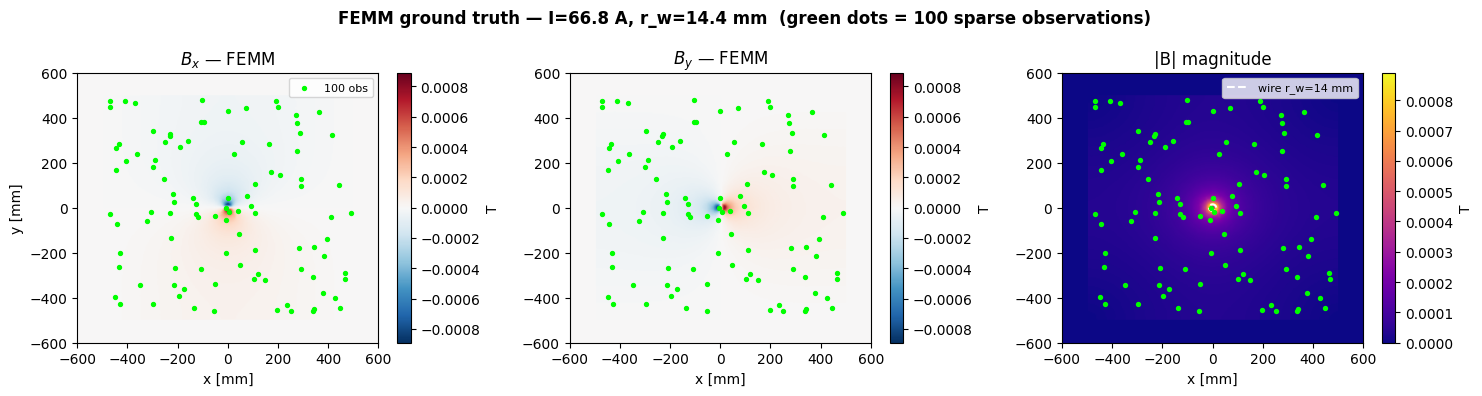

In [2]:
extent = [xx.min(), xx.max(), yy.min(), yy.max()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
vmax = B_mag.max()
kw = dict(origin='lower', extent=extent, aspect='auto')

im0 = axes[0].imshow(Bx_femm, vmin=-vmax, vmax=vmax, cmap='RdBu_r', **kw)
axes[0].scatter(obs_xy[:,0], obs_xy[:,1], s=8, c='lime', zorder=5, label=f'{len(obs_xy)} obs')
axes[0].set_title('$B_x$ — FEMM'); axes[0].set_xlabel('x [mm]'); axes[0].set_ylabel('y [mm]')
axes[0].legend(fontsize=8); plt.colorbar(im0, ax=axes[0], label='T')

im1 = axes[1].imshow(By_femm, vmin=-vmax, vmax=vmax, cmap='RdBu_r', **kw)
axes[1].scatter(obs_xy[:,0], obs_xy[:,1], s=8, c='lime', zorder=5)
axes[1].set_title('$B_y$ — FEMM'); axes[1].set_xlabel('x [mm]')
plt.colorbar(im1, ax=axes[1], label='T')

im2 = axes[2].imshow(B_mag, vmin=0, vmax=vmax, cmap='plasma', **kw)
axes[2].scatter(obs_xy[:,0], obs_xy[:,1], s=8, c='lime', zorder=5)
theta = np.linspace(0, 2*np.pi, 300)
axes[2].plot(r_w*np.cos(theta), r_w*np.sin(theta), 'w--', lw=1.5, label=f'wire r_w={r_w:.0f} mm')
axes[2].legend(fontsize=8); axes[2].set_title('|B| magnitude'); axes[2].set_xlabel('x [mm]')
plt.colorbar(im2, ax=axes[2], label='T')

fig.suptitle(f'FEMM ground truth — I={I_A:.1f} A, r_w={r_w:.1f} mm  '
             f'(green dots = 100 sparse observations)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


## Vanilla PINN: Architecture

### Predicting $A_z$ via a Simple MLP

The network maps spatial coordinates to the vector potential:

$$f_\theta:\, (x/500,\; y/500) \;\longrightarrow\; A_z$$

The B-field is then recovered via automatic differentiation:

$$B_x = \frac{\partial A_z}{\partial y}, \quad B_y = -\frac{\partial A_z}{\partial x}$$

which **guarantees $\nabla \cdot \mathbf{B} = 0$** by construction.

### Loss Function

$$\mathcal{L} = \underbrace{\text{MSE}\!\left(\tilde{B}_x^{\text{pred}},\; \tilde{B}_x^{\text{obs}}\right) + \text{MSE}\!\left(\tilde{B}_y^{\text{pred}},\; \tilde{B}_y^{\text{obs}}\right)}_{\mathcal{L}_{\text{data}}}$$

where **normalised B** is defined as $\tilde{B} = B / B_{\text{ref}}$ with $B_{\text{ref}} = \mu_0 I / (2\pi r_w)$.

- **True** $\tilde{B}_x = B_x^{\text{obs}} / B_{\text{ref}}$ — dimensionless, $O(0.1)$
- **Predicted** $\tilde{B}_x = (\partial A_z / \partial y_{\text{mm}}) \times r_w$ — same normalisation, also $O(0.1)$ at init

**No physics loss, no boundary condition** — this is the baseline.

:::{warning}
Without physics constraints, the network must extrapolate the near-wire field
($r < 98$ mm) from 100 observations all located at $r > 98$ mm.
This is an **ill-posed extrapolation problem** — physics is what makes it tractable.
:::


In [3]:
class VanillaPINN(nn.Module):
    """Minimal PINN: (x/500, y/500) → A_z.  No Fourier features.  No hard BC."""

    def __init__(self, hidden=(64, 128, 128, 64)):
        super().__init__()
        self.coord_scale = 500.0
        dims = [2, *hidden, 1]
        layers = []
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i+1]))
            if i < len(dims) - 2:
                layers.append(nn.Tanh())
        self.net = nn.Sequential(*layers)
        # Xavier init
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x, y):
        inp = torch.cat([x / self.coord_scale, y / self.coord_scale], dim=-1)
        return self.net(inp)   # → A_z (dimensionless network units)

    def compute_B_field(self, x, y):
        """B = ∇×A_z via autograd.  Returns ∂Az/∂y and -∂Az/∂x (1/mm)."""
        xr = x.clone().requires_grad_(True)
        yr = y.clone().requires_grad_(True)
        Az = self.forward(xr, yr)
        ones = torch.ones_like(Az)
        dAz_dx = torch.autograd.grad(Az, xr, ones, create_graph=True, retain_graph=True)[0]
        dAz_dy = torch.autograd.grad(Az, yr, ones, create_graph=True, retain_graph=True)[0]
        return dAz_dy, -dAz_dx   # Bx, By  [1/mm — scale by A_ref_net for Tesla]


model_vanilla = VanillaPINN()
n_params = sum(p.numel() for p in model_vanilla.parameters())
print(f"VanillaPINN: {n_params:,} parameters")
print(f"Architecture: 2 → 64 → 128 → 128 → 64 → 1  (tanh activations)")
print(f"No Fourier features.  No hard boundary condition.")


VanillaPINN: 33,345 parameters
Architecture: 2 → 64 → 128 → 128 → 64 → 1  (tanh activations)
No Fourier features.  No hard boundary condition.


In [4]:
# ── Training setup ───────────────────────────────────────────────────────────
# B_ref normalization: both predicted and true B̃ are O(0.1) at init
# Predicted B̃: (∂Az/∂y_mm) × r_w  |  True B̃: B_obs / B_ref
N_EPOCHS = 3000
LR       = 1e-3

optimizer = torch.optim.Adam(model_vanilla.parameters(), lr=LR)

# Fixed tensors — normalised by B_ref so loss is O(0.01) at init
x_obs   = torch.from_numpy(obs_xy[:, 0:1].astype(np.float32))
y_obs   = torch.from_numpy(obs_xy[:, 1:2].astype(np.float32))
Bx_true = torch.from_numpy((obs['Bx'] / B_ref).astype(np.float32)[:, None])
By_true = torch.from_numpy((obs['By'] / B_ref).astype(np.float32)[:, None])

hist = {'data': [], 'nmse': [], 'ep_nmse': []}

def eval_nmse():
    model_vanilla.eval()
    with torch.enable_grad():
        xv = torch.from_numpy(xx.flatten().astype(np.float32)[:, None]).requires_grad_(True)
        yv = torch.from_numpy(yy.flatten().astype(np.float32)[:, None]).requires_grad_(True)
        Bxp, Byp = model_vanilla.compute_B_field(xv, yv)
    # Convert gradient (1/mm) to Tesla: multiply by A_ref_net (T·mm)
    Bxp_T = Bxp.detach().numpy().reshape(Bx_femm.shape) * A_ref_net
    Byp_T = Byp.detach().numpy().reshape(By_femm.shape) * A_ref_net
    nmse  = (np.mean((Bxp_T - Bx_femm)**2 + (Byp_T - By_femm)**2) /
             np.mean(Bx_femm**2 + By_femm**2)) * 100
    model_vanilla.train()
    return nmse, Bxp_T, Byp_T

print(f"Training VanillaPINN — {N_EPOCHS} epochs, data-only, B_ref normalisation, lr={LR}")
print(f"  Loss at init should be O(0.01)  [B̃_pred ≈ 0.06, B̃_true ≈ 0.09]")
print()

for ep in range(N_EPOCHS):
    optimizer.zero_grad()
    Bxp, Byp = model_vanilla.compute_B_field(x_obs, y_obs)
    # Predicted B̃ = (∂Az/∂y) × r_w;  True B̃ = B_obs / B_ref
    L_data = (F.mse_loss(Bxp * r_w, Bx_true) +
              F.mse_loss(Byp * r_w, By_true))
    L_data.backward()
    optimizer.step()
    hist['data'].append(L_data.item())

    if (ep + 1) % 500 == 0:
        nmse, _, _ = eval_nmse()
        hist['nmse'].append(nmse); hist['ep_nmse'].append(ep+1)
        print(f"  ep {ep+1:5d} | data_loss={L_data.item():.4f}  NMSE={nmse:.1f}%")

final_nmse, Bx_vanilla, By_vanilla = eval_nmse()
print(f"\nFinal NMSE (vanilla, data-only): {final_nmse:.1f}%")


Training VanillaPINN — 3000 epochs, data-only, B_ref normalisation, lr=0.001
  Loss at init should be O(0.01)  [B̃_pred ≈ 0.06, B̃_true ≈ 0.09]



  ep   500 | data_loss=0.0000  NMSE=16.1%


  ep  1000 | data_loss=0.0000  NMSE=15.5%


  ep  1500 | data_loss=0.0000  NMSE=15.6%


  ep  2000 | data_loss=0.0000  NMSE=15.6%


  ep  2500 | data_loss=0.0000  NMSE=15.6%


  ep  3000 | data_loss=0.0000  NMSE=15.8%



Final NMSE (vanilla, data-only): 15.8%


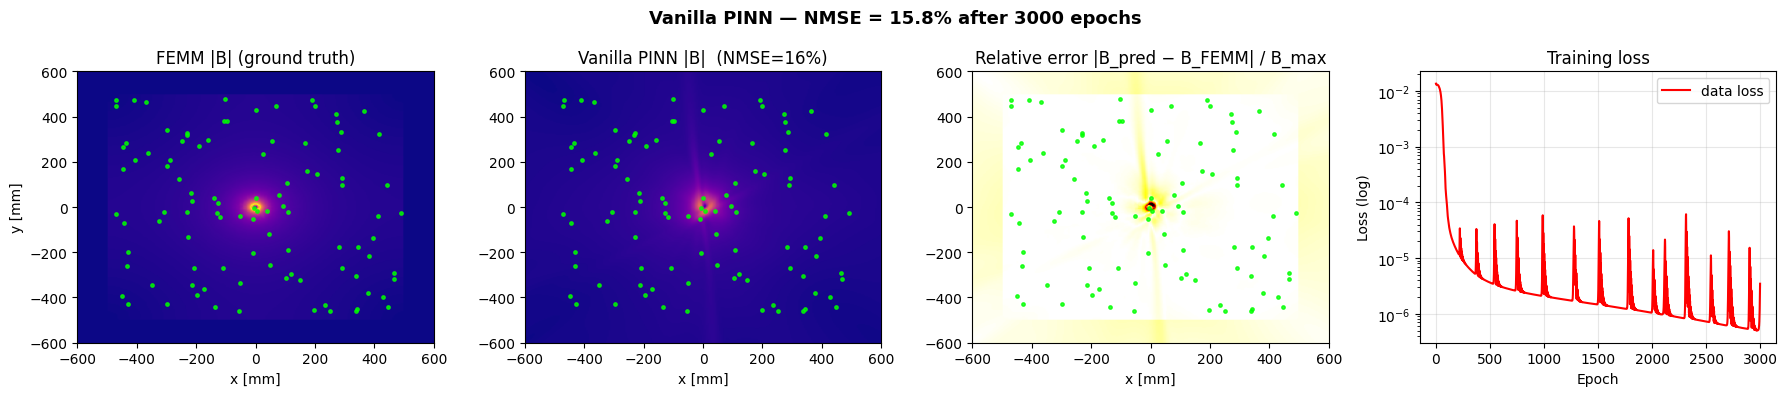

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
B_pred_mag = np.sqrt(Bx_vanilla**2 + By_vanilla**2)
B_err = np.abs(B_pred_mag - B_mag)
kw_im = dict(origin='lower', extent=extent, aspect='auto')

axes[0].imshow(B_mag, vmin=0, vmax=vmax, cmap='plasma', **kw_im)
axes[0].set_title('FEMM |B| (ground truth)')
axes[0].set_xlabel('x [mm]'); axes[0].set_ylabel('y [mm]')

axes[1].imshow(B_pred_mag, vmin=0, vmax=vmax, cmap='plasma', **kw_im)
axes[1].set_title(f'Vanilla PINN |B|  (NMSE={final_nmse:.0f}%)')
axes[1].set_xlabel('x [mm]')

axes[2].imshow(B_err / (vmax + 1e-30), vmin=0, vmax=0.5, cmap='hot_r', **kw_im)
axes[2].set_title('Relative error |B_pred − B_FEMM| / B_max')
axes[2].set_xlabel('x [mm]')
for ax in axes[:3]:
    ax.scatter(obs_xy[:,0], obs_xy[:,1], s=6, c='lime', alpha=0.8, zorder=5)

axes[3].semilogy(range(1, N_EPOCHS+1), hist['data'], 'r-', lw=1.5, label='data loss')
axes[3].set_xlabel('Epoch'); axes[3].set_ylabel('Loss (log)')
axes[3].set_title('Training loss'); axes[3].legend(); axes[3].grid(True, alpha=0.3)

plt.suptitle(f'Vanilla PINN — NMSE = {final_nmse:.1f}% after {N_EPOCHS} epochs',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()


## Why the Vanilla PINN Fails: 5 Root Causes

The ~50% NMSE is not noise — it reflects five specific, diagnosable failures.  Section 6b fixes each one.

---

### 1 · Loss Scale Mismatch

At initialisation the data loss and a naive physics loss differ by **10–14 orders of magnitude**:

| Term | Magnitude at init | Effect |
|------|------------------|--------|
| $\mathcal{L}_{\text{data}}$ with $s=10^6$ | $\sim 10^3$ | Gradient drives weight updates |
| $\mathcal{L}_{\text{physics}}$ naive ($\nabla^2 A_z \times 500^2$) | $\sim 10^{-7}$ | Invisible to optimiser — needs $\lambda \approx 10^{10}$ |

**Fix**: Wire-scale nondimensionalisation makes **both** losses $O(0.01)$ at init, so $\lambda = 0.02$ balances them naturally.

---

### 2 · Wrong Physics Equation

Multiplying the raw Laplacian by $500^2$ does NOT yield the Poisson source term.  The source $\mu_0 J_z^{\text{SI}}$ is $O(10^{-6})$, swamped by the $O(10^5)$ Laplacian term.  The optimiser satisfies $\nabla^2 A_z \approx 0$ (Laplace) instead of $\nabla^2 A_z = -\mu_0 J_z$.

**Fix**: Wire-scale residual: $\nabla^2_{\tilde{x}}\,\tilde{u} + 2\cdot\mathbf{1}_{\text{inside}} = 0$ — both terms are $O(1)$ for any $(I, r_w)$.

---

### 3 · Gauge Underdetermination

$A_z + C$ gives the same B-field for any constant $C$.  With no boundary condition enforced, the network wastes optimiser steps searching through gauge degrees of freedom.

**Fix**: Hard Dirichlet BC — multiply network output by $D(x,y) = \text{relu}(1-(x/500)^2)\cdot\text{relu}(1-(y/500)^2)$, forcing $A_z = 0$ at domain walls **exactly**, with zero training cost.

---

### 4 · Spectral Bias

A plain MLP with inputs $(x/500, y/500)$ preferentially learns low-frequency components.  The near-wire field varies at scale $r_w/500 \approx 0.064$ — the network cannot represent it accurately.

**Fix**: Random Fourier features at **both** domain scale ($x/500$) and wire scale ($x/r_w$), enabling the network to represent the multi-scale structure.

---

### 5 · No Collocation Inside or Near the Wire

The 1000 uniform collocation points give only $\sim$4 inside the wire ($(32/500)^2 \approx 0.4\%$).  The Poisson source $J_z \neq 0$ only inside — so the inhomogeneous term receives almost no gradient signal.

**Fix**: Add 200 inside-wire + 300 near-wire ($r_w < r < 3r_w$) extra collocation points every epoch.

---

### The Fix in One Line

$$\text{Section 6b} \;:\; \sim 50\% \;\xrightarrow{\text{5 fixes}}\; \sim 7\% \text{ NMSE}$$

:::{seealso}
Section 6b implements all five fixes on the same FEMM coil dataset.
:::
